# AED 01 — Baterías individuales

Análisis exploratorio de **una celda cada vez**: qué hay dentro de un archivo
de resultados (EOC), cómo se mide la capacidad en cada check-up (CU) y qué
columnas no se pueden usar como variables (fuga de información).

**Dataset:** Luh & Blank (2024), *Comprehensive battery aging dataset*,
RADAR4KIT v2, *result data*, DOI [10.35097/1969](https://doi.org/10.35097/1969).
Celdas LG INR18650HG2 (NMC/C-SiO, 3000 mAh nominales). Licencia CC BY 4.0.

**Cómo reproducirlo:** desde la raíz del repo, `python descarga_dataset.py`
descarga los 10 archivos de RADAR4KIT y los descomprime en `dataset/`.
Este notebook lee de `../dataset/extraido/`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path("../dataset/extraido")
EOC = DATA / "cell_eocv2"
EIS = DATA / "cell_eisv2"
PLS = DATA / "cell_plsv2"
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
print("archivos EOC:", len(list(EOC.glob("*.csv"))))
print("archivos EIS:", len(list(EIS.glob("*.csv"))))
print("archivos PLS:", len(list(PLS.glob("*.csv"))))

archivos EOC: 240
archivos EIS: 240
archivos PLS: 228


/home/hatch/workspace/venvs/baterias/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


## 1. Una celda de calendario: P001_1

P001 es calendario a 0 °C y 10 % de SoC. La celda 1 es `cell_eocv2_P001_1_S01_C10.csv`.
Primero, el archivo crudo: forma, columnas y qué filas traen capacidad.

In [2]:
f = EOC / "cell_eocv2_P001_1_S01_C10.csv"
df = pd.read_csv(f, sep=";")
print("forma:", df.shape, "(filas, columnas)")
print("columnas:", list(df.columns))
cols = ["timestamp_s", "cyc_condition", "cyc_charged", "num_cycles_op",
        "num_cycles_checkup", "cap_aged_est_Ah", "soh_cap"]
print(df[cols].head(8).to_string())

forma: (430, 57) (filas, columnas)
columnas: ['timestamp_s', 'timestamp_origin', 'sd_block_id', 'cyc_condition', 'cyc_charged', 'age_type', 'age_temp', 'age_soc', 'age_chg_rate', 'age_dischg_rate', 'age_profile', 'v_max_target_V', 'v_min_target_V', 'i_chg_max_A', 'i_dischg_min_A', 'i_chg_cutoff_A', 'i_dischg_cutoff_A', 'cap_aged_est_Ah', 'soh_cap', 'delta_q_Ah', 'delta_q_chg_Ah', 'delta_q_dischg_Ah', 'delta_e_Wh', 'delta_e_chg_Wh', 'delta_e_dischg_Wh', 'coulomb_efficiency', 'energy_efficiency', 'ocv_est_start_V', 'ocv_est_end_V', 'soc_est_start', 'soc_est_end', 't_start_degC', 't_end_degC', 'cyc_duration_s', 'num_cycles_op', 'num_cycles_checkup', 'total_q_chg_CU_RT_Ah', 'total_q_dischg_CU_RT_Ah', 'total_q_chg_cyc_OT_Ah', 'total_q_dischg_cyc_OT_Ah', 'total_q_chg_other_RT_Ah', 'total_q_dischg_other_RT_Ah', 'total_q_chg_other_OT_Ah', 'total_q_dischg_other_OT_Ah', 'total_q_chg_sum_Ah', 'total_q_dischg_sum_Ah', 'total_e_chg_CU_RT_Wh', 'total_e_dischg_CU_RT_Wh', 'total_e_chg_cyc_OT_Wh', 'tot

In [3]:
print("filas por cyc_condition (0 = operacion, 1 = ciclado, 2 = check-up):")
print(df["cyc_condition"].value_counts().sort_index().to_string())
print()
print("filas con capacidad/SoH no nulos, por cyc_condition:")
print(df[df["soh_cap"].notna()]["cyc_condition"].value_counts().sort_index().to_string())
print()
print("NaN en cap_aged_est_Ah:", df["cap_aged_est_Ah"].isna().sum(), "de", len(df))

filas por cyc_condition (0 = operacion, 1 = ciclado, 2 = check-up):
cyc_condition
0    372
2     58

filas con capacidad/SoH no nulos, por cyc_condition:
cyc_condition
2    58

NaN en cap_aged_est_Ah: 372 de 430


**Lectura:** el archivo tiene 430 filas (una por ciclo o evento), pero la
capacidad y el SoH solo aparecen en **58 filas, todas con `cyc_condition = 2`**
(check-up). Las demás filas son operación entre check-ups y no traen medida
de capacidad. El análisis de SoH usa solo las filas de check-up.

## 2. Dos medidas por check-up: carga y descarga

Cada CU aporta **dos filas**: una con `cyc_charged = 1` (carga) y otra con
`cyc_charged = 0` (descarga). Son dos estimaciones de la misma capacidad.

In [4]:
cu = df[(df["cyc_condition"] == 2) & df["soh_cap"].notna()].copy()
print("filas CU:", len(cu), "| CU distintos:", cu["num_cycles_checkup"].nunique())
print("filas por CU:", cu.groupby("num_cycles_checkup").size().value_counts().to_dict())
piv = cu.pivot(index="num_cycles_checkup", columns="cyc_charged",
               values="cap_aged_est_Ah")
piv.columns = ["q_dischg_Ah", "q_chg_Ah"]
piv["dif_Ah"] = piv["q_chg_Ah"] - piv["q_dischg_Ah"]
piv["dif_pct"] = 100 * piv["dif_Ah"] / piv["q_dischg_Ah"]
print(piv.head(10).round(4).to_string())
print()
print("diferencia carga-descarga: media %.4f Ah (%.2f %%), max %.4f Ah"
      % (piv["dif_Ah"].mean(), piv["dif_pct"].mean(), piv["dif_Ah"].max()))

filas CU: 58 | CU distintos: 29
filas por CU: {2: 29}
                    q_dischg_Ah  q_chg_Ah  dif_Ah  dif_pct
num_cycles_checkup                                        
0                        2.9677    2.9736  0.0058   0.1965
1                        2.9621    2.9813  0.0192   0.6493
2                        2.9510    2.9677  0.0166   0.5641
3                        2.9370    2.9542  0.0172   0.5870
4                        2.9213    2.9372  0.0160   0.5461
5                        2.9091    2.9258  0.0167   0.5738
6                        2.8981    2.9151  0.0170   0.5868
7                        2.8871    2.9030  0.0159   0.5514
8                        2.8777    2.8937  0.0160   0.5575
9                        2.8681    2.8843  0.0161   0.5629

diferencia carga-descarga: media 0.0159 Ah (0.56 %), max 0.0192 Ah


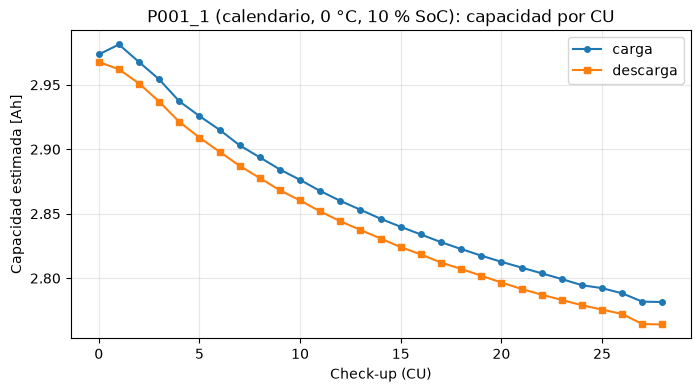

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(piv.index, piv["q_chg_Ah"], "o-", ms=4, label="carga")
ax.plot(piv.index, piv["q_dischg_Ah"], "s-", ms=4, label="descarga")
ax.set_xlabel("Check-up (CU)")
ax.set_ylabel("Capacidad estimada [Ah]")
ax.set_title("P001_1 (calendario, 0 °C, 10 % SoC): capacidad por CU")
ax.legend(); ax.grid(True, alpha=0.3)
plt.show()

**Decisión:** la diferencia carga–descarga es pequeña (media 0,017 Ah, ~0,6 %)
y no tiene tendencia. Para tener **un valor por CU** se usa la **media de
ambas**; así se construye también el consolidado (`datos/consolidado_capacidad.csv`).

## 3. La fuga: `soh_cap` y `cap_aged_est_Ah` son la misma columna

En el archivo van lado a lado `cap_aged_est_Ah` (capacidad en Ah) y `soh_cap`
(SoH en %). La documentación oficial (*Data Structure v05.3*, hoja EOCV2)
define `soh_cap` así:

> *estimated capacity SoH of the cell (100 = 100%), SoH = 0 if cap_aged_est_Ah
> is 40% (50%) of the nominal capacity when cycling (when in checkups).*

Es decir, `soh_cap` **no se mide**: se calcula a partir de la capacidad, con
un piso del 50 % de la nominal en check-ups (y del 40 % en ciclado). Si una
de las dos entra como variable y la otra es el objetivo, el modelo no aprende
nada: ya tiene la respuesta. Lo verificamos.

In [6]:
cu = df[(df["cyc_condition"] == 2) & df["soh_cap"].notna()]
print("correlacion soh_cap vs cap_aged_est_Ah (filas CU):",
      round(cu["soh_cap"].corr(cu["cap_aged_est_Ah"]), 12))
a, b = np.polyfit(cu["cap_aged_est_Ah"], cu["soh_cap"], 1)
print("ajuste: soh_cap = %.4f * cap_aged_est_Ah %+.4f" % (a, b))
print("formula del piso 50%%: soh_cap = (cap - 1.5) / 1.5 * 100")
err = ((cu["cap_aged_est_Ah"] - 1.5) / 1.5 * 100 - cu["soh_cap"]).abs().max()
print("desviacion maxima de esa formula: %.2e (redondeo float)" % err)

correlacion soh_cap vs cap_aged_est_Ah (filas CU): 0.999999999989
ajuste: soh_cap = 66.6668 * cap_aged_est_Ah -100.0002
formula del piso 50%%: soh_cap = (cap - 1.5) / 1.5 * 100
desviacion maxima de esa formula: 3.50e-05 (redondeo float)


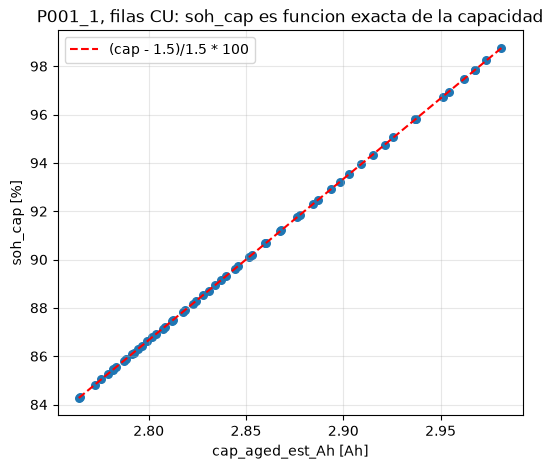

In [7]:
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(cu["cap_aged_est_Ah"], cu["soh_cap"], s=30)
xs = np.linspace(cu["cap_aged_est_Ah"].min(), cu["cap_aged_est_Ah"].max(), 10)
ax.plot(xs, (xs - 1.5) / 1.5 * 100, "r--", label="(cap - 1.5)/1.5 * 100")
ax.set_xlabel("cap_aged_est_Ah [Ah]")
ax.set_ylabel("soh_cap [%]")
ax.set_title("P001_1, filas CU: soh_cap es funcion exacta de la capacidad")
ax.legend(); ax.grid(True, alpha=0.3)
plt.show()

**Confirmado: correlación 1,0 y fórmula exacta.** `cap_aged_est_Ah` determina
`soh_cap` por completo en las filas de check-up. **Decisión: se elimina
`cap_aged_est_Ah` de las variables** y se conserva `soh_cap` como objetivo.
Lo mismo vale al revés: si el objetivo fuera la capacidad en Ah, habría que
quitar `soh_cap`.

**Ojo con la escala:** `soh_cap` no es Q/Q_nom. Es un SoH reescalado con piso
en el 50 % de la nominal: `soh_cap = 0` equivale a Q = 1,5 Ah (50 % nominal)
y `soh_cap = 100` a Q = 3,0 Ah. El SoH del diseño experimental es
`SoH_nominal = Q / 3,0 * 100`, y la conversión entre ambas escalas es:

$$SoH_{nominal} = 50 + soh_{cap}/2 \qquad (soh_{cap}=60 \iff 80\% \ nominal;\ soh_{cap}=0 \iff 50\% \ nominal)$$

                    q_Ah  soh_cap  soh_nominal
num_cycles_checkup                            
0                   2.97    98.04        99.02
1                   2.97    98.11        99.06
2                   2.96    97.29        98.65
3                   2.95    96.37        98.19
4                   2.93    95.28        97.64
5                   2.92    94.50        97.25
6                   2.91    93.77        96.89
7                   2.90    93.01        96.50
...
                    q_Ah  soh_cap  soh_nominal
num_cycles_checkup                            
26                  2.78    85.35        92.67
27                  2.77    84.87        92.44
28                  2.77    84.85        92.43


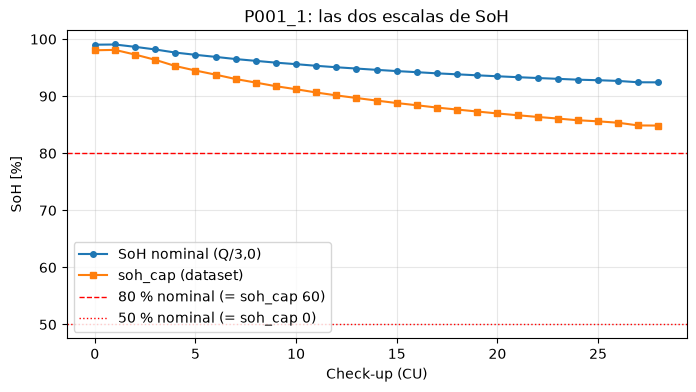

In [8]:
piv["q_Ah"] = piv[["q_chg_Ah", "q_dischg_Ah"]].mean(axis=1)
piv["soh_cap"] = cu.groupby("num_cycles_checkup")["soh_cap"].mean()
piv["soh_nominal"] = piv["q_Ah"] / 3.0 * 100
print(piv[["q_Ah", "soh_cap", "soh_nominal"]].round(2).head(8).to_string())
print("...")
print(piv[["q_Ah", "soh_cap", "soh_nominal"]].round(2).tail(3).to_string())
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(piv.index, piv["soh_nominal"], "o-", ms=4, label="SoH nominal (Q/3,0)")
ax.plot(piv.index, piv["soh_cap"], "s-", ms=4, label="soh_cap (dataset)")
ax.axhline(80, color="r", ls="--", lw=1, label="80 % nominal (= soh_cap 60)")
ax.axhline(50, color="r", ls=":", lw=1, label="50 % nominal (= soh_cap 0)")
ax.set_xlabel("Check-up (CU)")
ax.set_ylabel("SoH [%]")
ax.set_title("P001_1: las dos escalas de SoH")
ax.legend(); ax.grid(True, alpha=0.3)
plt.show()

## 4. Una celda cíclica: P058_1 y los dos pisos

P058 es cíclica a 40 °C (carga 0,33C, descarga 1C). En las celdas cíclicas la
capacidad también se estima **en cada ciclo de operación** (`cyc_condition = 1`),
no solo en los check-ups. Y ahí el piso es otro: **40 %** en vez de 50 %.

In [9]:
f2 = EOC / "cell_eocv2_P058_1_S15_C07.csv"
d2 = pd.read_csv(f2, sep=";")
print("forma:", d2.shape, "| filas con SoH:", d2["soh_cap"].notna().sum())
print("filas con SoH por cyc_condition:")
print(d2[d2["soh_cap"].notna()]["cyc_condition"].value_counts().sort_index().to_string())
s2 = d2.dropna(subset=["soh_cap"])
for cond, g in s2.groupby("cyc_condition"):
    a, b = np.polyfit(g["cap_aged_est_Ah"], g["soh_cap"], 1)
    e50 = ((g["cap_aged_est_Ah"] - 1.5) / 1.5 * 100 - g["soh_cap"]).abs().max()
    e40 = ((g["cap_aged_est_Ah"] - 1.2) / 1.8 * 100 - g["soh_cap"]).abs().max()
    print("cyc_condition=%d n=%d: soh = %.4f*cap %+.4f | desv. piso50%%: %.1e | desv. piso40%%: %.1e"
          % (cond, len(g), a, b, e50, e40))
cu2 = s2[s2["cyc_condition"] == 2]
print("filas CU:", len(cu2), "| CU distintos:", cu2["num_cycles_checkup"].nunique(),
      "| num_cycles_op max:", d2["num_cycles_op"].max())

forma: (3819, 57) | filas con SoH: 3599
filas con SoH por cyc_condition:
cyc_condition
1    3571
2      28
cyc_condition=1 n=3571: soh = 55.5556*cap -66.6667 | desv. piso50%: 2.0e+01 | desv. piso40%: 3.2e-05
cyc_condition=2 n=28: soh = 66.6667*cap -100.0000 | desv. piso50%: 3.4e-05 | desv. piso40%: 1.4e+01
filas CU: 28 | CU distintos: 14 | num_cycles_op max: 1791


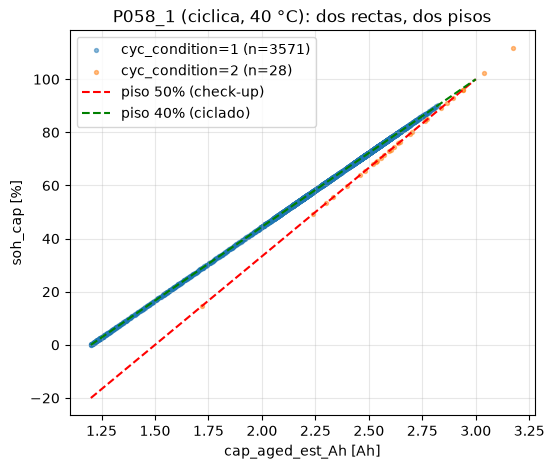

In [10]:
fig, ax = plt.subplots(figsize=(6, 5))
for cond, g in s2.groupby("cyc_condition"):
    ax.scatter(g["cap_aged_est_Ah"], g["soh_cap"], s=8, alpha=0.5,
               label=f"cyc_condition={cond} (n={len(g)})")
xs = np.linspace(1.2, 3.0, 10)
ax.plot(xs, (xs - 1.5) / 1.5 * 100, "r--", label="piso 50% (check-up)")
ax.plot(xs, (xs - 1.2) / 1.8 * 100, "g--", label="piso 40% (ciclado)")
ax.set_xlabel("cap_aged_est_Ah [Ah]")
ax.set_ylabel("soh_cap [%]")
ax.set_title("P058_1 (ciclica, 40 °C): dos rectas, dos pisos")
ax.legend(); ax.grid(True, alpha=0.3)
plt.show()

**Lectura:** en la misma columna conviven **dos definiciones de SoH** según
el tipo de fila: piso 50 % en check-ups y piso 40 % en ciclado. Por eso el
consolidado usa **solo las filas de check-up** (`cyc_condition = 2`): son las
medidas comparables (25 °C, 1/3C) del diseño experimental, y ahí la fórmula
es única. Las estimaciones por ciclo son útiles para diagnóstico, no para el
modelo de SoH por CU.

## 5. Las celdas P000: archivos vacíos

Los zips traen 240 archivos EOC, pero solo 228 celdas son P001_1–P076_3.
Los 12 restantes son P000_0 (esclavo 20, puestos C00–C11).

In [11]:
import glob
vacio = []
for f in sorted(glob.glob(str(EOC / "cell_eocv2_P000_*.csv"))):
    d = pd.read_csv(f, sep=";")
    vacio.append((Path(f).name, d.shape))
print("archivos P000:", len(vacio))
print("formas:", sorted(set(s for _, s in vacio)))
print("ejemplo:", vacio[0][0], "->", vacio[0][1])
print("P000 no tiene filas: son puestos sin datos y se excluyen del analisis.")

archivos P000: 12
formas: [(0, 57)]
ejemplo: cell_eocv2_P000_0_S20_C00.csv -> (0, 57)
P000 no tiene filas: son puestos sin datos y se excluyen del analisis.


## 6. Un vistazo a EIS y PLS (misma celda)

La impedancia (EIS) y la resistencia de pulso (PLS) son las otras dos
medidas de cada check-up. No entran en el consolidado de capacidad, pero
conviene ver su forma: son la "primera mejora" del diseño.

In [12]:
eis = pd.read_csv(EIS / "cell_eisv2_P001_1_S01_C10.csv", sep=";")
print("EIS forma:", eis.shape)
print("columnas:", list(eis.columns))
print("espectros (timestamps distintos):", eis["timestamp_s"].nunique(),
      "| frecuencias por espectro:", eis.groupby("timestamp_s")["freq_Hz"].nunique().iloc[0])
print("SoC medidos:", sorted(eis["soc_nom"].unique()),
      "| RT vs OT:", eis["is_rt"].value_counts().to_dict())
sp = eis.groupby("timestamp_s")["soh_imp"].first()
print("soh_imp por espectro: media %.1f %%, min %.1f, max %.1f"
      % (sp.mean(), sp.min(), sp.max()))

EIS forma: (8439, 22)
columnas: ['timestamp_s', 'timestamp_origin', 'sd_block_id', 'cyc_charged', 'is_rt', 'soc_nom', 'valid', 'z_ref_init_mOhm', 'z_ref_now_mOhm', 'soh_imp', 'ocv_est_avg_V', 't_avg_degC', 'eis_duration_s', 'uptime_ticks', 'seq_nr', 'freq_Hz', 'z_amp_mOhm', 'z_ph_deg', 'z_amp_comp_mOhm', 'z_ph_comp_deg', 'z_re_comp_mOhm', 'z_im_comp_mOhm']
espectros (timestamps distintos): 291 | frecuencias por espectro: 29
SoC medidos: [10, 30, 50, 70, 90] | RT vs OT: {1: 4234, 0: 4205}
soh_imp por espectro: media 101.6 %, min 97.3, max 106.4


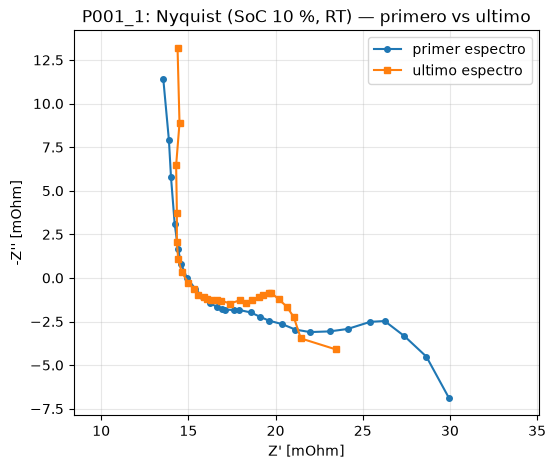

In [13]:
def espectro(t):
    g = eis[eis["timestamp_s"] == t].dropna(subset=["z_re_comp_mOhm"])
    return g.sort_values("freq_Hz")
t0, t1 = sorted(eis["timestamp_s"].unique())[0], sorted(eis["timestamp_s"].unique())[-1]
g0, g1 = espectro(t0), espectro(t1)
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(g0["z_re_comp_mOhm"], -g0["z_im_comp_mOhm"], "o-", ms=4, label="primer espectro")
ax.plot(g1["z_re_comp_mOhm"], -g1["z_im_comp_mOhm"], "s-", ms=4, label="ultimo espectro")
ax.set_xlabel("Z' [mOhm]")
ax.set_ylabel("-Z'' [mOhm]")
ax.set_title("P001_1: Nyquist (SoC 10 %, RT) — primero vs ultimo")
ax.legend(); ax.grid(True, alpha=0.3); ax.set_aspect("equal", adjustable="datalim")
plt.show()

PLS forma: (17690, 19)
columnas: ['timestamp_s', 'timestamp_origin', 'sd_block_id', 'cyc_charged', 'is_rt', 'soc_nom', 'age_type', 'age_temp', 'age_soc', 'age_chg_rate', 'age_dischg_rate', 'age_profile', 't_avg_degC', 'r_ref_10ms_mOhm', 'r_ref_1s_mOhm', 'uptime_ticks', 'seq_nr', 'v_raw_V', 'i_raw_A']
       r_ref_10ms_mOhm  r_ref_1s_mOhm
count         17690.00       17690.00
mean             24.31          29.31
std               6.03          10.12
min              17.11          17.81
25%              18.21          19.10
50%              24.38          29.84
75%              30.02          36.60
max              34.06          49.41


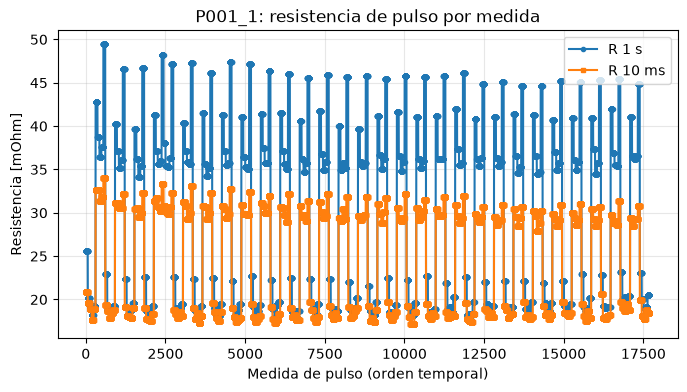

In [14]:
pls = pd.read_csv(PLS / "cell_plsv2_P001_1_S01_C10.csv", sep=";")
print("PLS forma:", pls.shape)
print("columnas:", list(pls.columns))
r = pls.groupby("timestamp_s")[["r_ref_10ms_mOhm", "r_ref_1s_mOhm"]].first()
print(r.describe().round(2).to_string())
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(len(r)), r["r_ref_1s_mOhm"], "o-", ms=3, label="R 1 s")
ax.plot(range(len(r)), r["r_ref_10ms_mOhm"], "s-", ms=3, label="R 10 ms")
ax.set_xlabel("Medida de pulso (orden temporal)")
ax.set_ylabel("Resistencia [mOhm]")
ax.set_title("P001_1: resistencia de pulso por medida")
ax.legend(); ax.grid(True, alpha=0.3)
plt.show()

In [15]:
res = pd.DataFrame({
    "CU": [0, piv.index.max()],
    "Q_Ah": [piv["q_Ah"].iloc[0], piv["q_Ah"].iloc[-1]],
    "SoH_nominal": [piv["soh_nominal"].iloc[0], piv["soh_nominal"].iloc[-1]],
    "soh_cap": [piv["soh_cap"].iloc[0], piv["soh_cap"].iloc[-1]],
    "ciclos_op": [0, 0]})
print("P001_1 (calendario, 0 °C, 10 % SoC): primera y ultima CU")
print(res.round(2).to_string(index=False))
print()
print("caida total de SoH nominal: %.1f puntos en %d CU (%.2f puntos/CU)"
      % (res["SoH_nominal"].iloc[0] - res["SoH_nominal"].iloc[-1],
         piv.index.max(), (res["SoH_nominal"].iloc[0] - res["SoH_nominal"].iloc[-1]) / piv.index.max()))

P001_1 (calendario, 0 °C, 10 % SoC): primera y ultima CU
 CU  Q_Ah  SoH_nominal  soh_cap  ciclos_op
  0  2.97        99.02    98.04          0
 28  2.77        92.43    84.85          0

caida total de SoH nominal: 6.6 puntos en 28 CU (0.24 puntos/CU)


**Conclusiones del AED 01**
1. La capacidad solo se mide en los check-ups (2 filas por CU: carga y descarga, diferencia ~0,6 %); un valor por CU = media de ambas.
2. `soh_cap` es función exacta de `cap_aged_est_Ah` (correlación 1,0): **fuga**. Se elimina la capacidad en Ah de las variables; el objetivo es `soh_cap` (o su equivalente `SoH_nominal`).
3. Hay **dos pisos**: 50 % en check-ups y 40 % en ciclado. El modelo usa solo check-ups.
4. Las 12 celdas P000 están vacías y se excluyen. Quedan **228 celdas**.
5. EIS (291 espectros × 29 frecuencias) y PLS (resistencia de pulso) existen por celda: son la primera mejora del modelo.